# Day 14 · Pre-CNN foundations: from pixels to neurons

> **Not a course lab file — built from the Key Concepts "Pre-CNN Module" activities.** The course has no `CV-Week2-Lecture*.ipynb` for Day 14. This notebook works through every activity that module describes, so you have runnable code for each idea before the CNN lab (Day 15).

**Notes chapter:** `week-2/notes/07_pre_cnn_foundations.md`
**Run time:** about 1 minute on a laptop CPU. No downloads (all images ship with scikit-image and scikit-learn).

**What you will learn** (the Key Concepts' order: *pixels → features → ML → ANN → CNN*)
1. NumPy arrays **are** images; grayscale vs RGB; the rotate/flip activity and why transformations hurt recognition.
2. The **dot product** as a similarity measure.
3. **Convolution = sliding dot product**, by hand with an edge kernel, then the same with `cv2.filter2D` and `nn.Conv2d`.
4. **Derivatives and gradients** ("how steep the hill is") and a tiny **gradient descent**.
5. **Mean, variance** and why **normalisation** matters.
6. **Supervised vs unsupervised** learning side by side: kNN with labels vs k-means without.
7. An **artificial neuron** computed by hand: z = Σ wᵢxᵢ + b → f(z).
8. A small **feed-forward network (MLP)** trained on digits, with accuracy per epoch.
9. The **bridge to CNNs**: why dense layers do not scale to images.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from skimage import data as skdata
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from threadpoolctl import threadpool_limits

threadpool_limits(2); torch.set_num_threads(2)       # optional: use at most 2 CPU cores
np.random.seed(0); torch.manual_seed(0)
plt.rcParams["figure.dpi"] = 80
print("NumPy", np.__version__, "| OpenCV", cv2.__version__, "| PyTorch", torch.__version__)

NumPy 2.5.3 | OpenCV 5.0.0 | PyTorch 2.14.1+cu130


## 1 · Programming basics: an image is a NumPy array

> **Analogy (Key Concepts):** a NumPy array is like an **Excel sheet where each cell holds a number, with superpowers for maths**. A grayscale image is one sheet; an RGB image is three stacked sheets (red, green, blue). Pixels are **Lego blocks**: arrange the numbers and you build the picture.

shape: (6, 6) | dtype: uint8
[[  0   0   0   0   0   0]
 [  0   0 255 255   0   0]
 [  0   0 255 255   0   0]
 [  0   0 255 255   0   0]
 [  0   0 255 255   0   0]
 [  0   0   0   0   0   0]]

grayscale photo: (512, 512) uint8 | min/max: 0 255
colour photo   : (512, 512, 3) -> 3 channels; pixel (100, 200) = [81 57 17] (R, G, B)


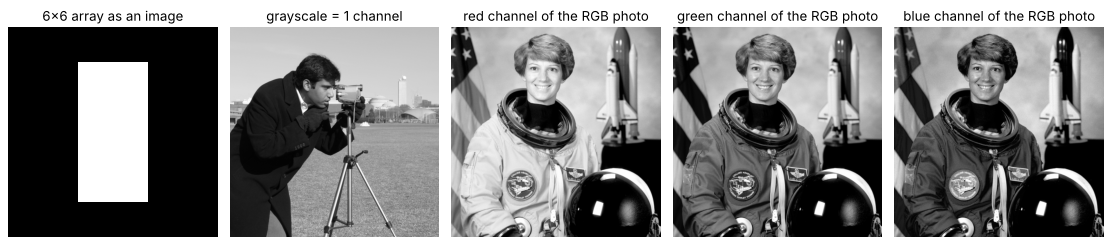

In [2]:
# Build a tiny image by hand: 0 = black, 255 = white
tiny = np.zeros((6, 6), dtype=np.uint8)
tiny[1:5, 2:4] = 255                      # a white vertical bar (rows 1-4, columns 2-3)
print("shape:", tiny.shape, "| dtype:", tiny.dtype)
print(tiny)

cam = skdata.camera()                      # a 512x512 grayscale photo (ships with scikit-image)
rgb = skdata.astronaut()                   # a 512x512 colour photo, shape (H, W, 3)
print("\ngrayscale photo:", cam.shape, cam.dtype, "| min/max:", cam.min(), cam.max())
print("colour photo   :", rgb.shape, "-> 3 channels; pixel (100, 200) =", rgb[100, 200], "(R, G, B)")

fig, ax = plt.subplots(1, 5, figsize=(14, 3))
ax[0].imshow(tiny, cmap="gray", vmin=0, vmax=255); ax[0].set_title("6x6 array as an image")
ax[1].imshow(cam, cmap="gray"); ax[1].set_title("grayscale = 1 channel")
for a, c, name in zip(ax[2:], range(3), ["red", "green", "blue"]):
    a.imshow(rgb[:, :, c], cmap="gray"); a.set_title(f"{name} channel of the RGB photo")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

crop (200, 200) | small (128, 128)
Why clip? uint8 wraps around: [4] (250 + 10 = 4!)


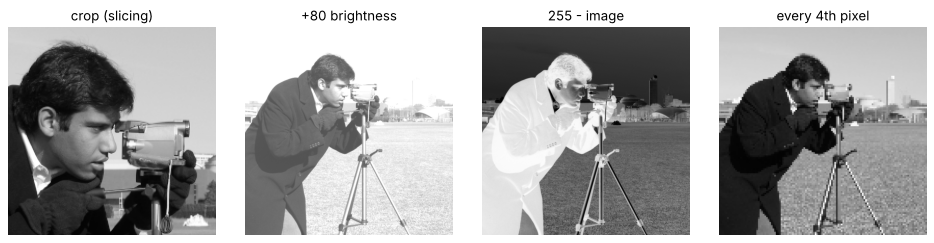

In [3]:
# Everyday array operations = everyday image operations
crop = cam[50:250, 150:350]                 # slicing = cropping (rows first, then columns)
brighter = np.clip(cam.astype(np.int16) + 80, 0, 255).astype(np.uint8)   # add a number = brighten (clip to avoid wrap-around)
negative = 255 - cam                        # invert
small = cam[::4, ::4]                       # every 4th pixel = crude down-scaling
print("crop", crop.shape, "| small", small.shape)
print("Why clip? uint8 wraps around:", np.array([250], np.uint8) + np.array([10], np.uint8), "(250 + 10 = 4!)")

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, im, t in zip(ax, [crop, brighter, negative, small], ["crop (slicing)", "+80 brightness", "255 - image", "every 4th pixel"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

### Activity: rotate and flip an image, then discuss how transformations affect recognition

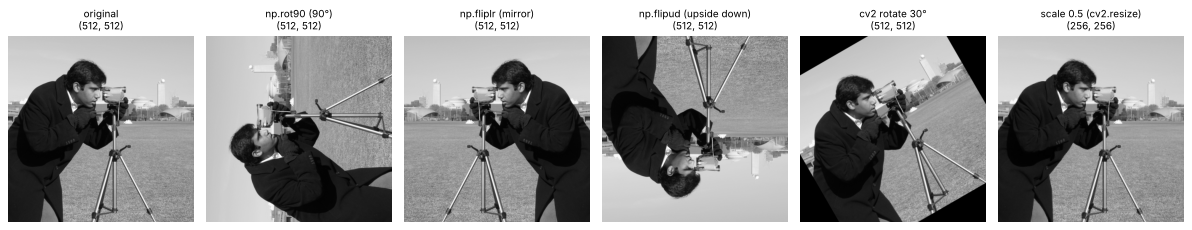

In [4]:
h, w = cam.shape
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0)       # rotate 30 degrees about the centre
versions = {
    "original": cam,
    "np.rot90 (90°)": np.rot90(cam),
    "np.fliplr (mirror)": np.fliplr(cam),
    "np.flipud (upside down)": np.flipud(cam),
    "cv2 rotate 30°": cv2.warpAffine(cam, M, (w, h)),
    "scale 0.5 (cv2.resize)": cv2.resize(cam, None, fx=0.5, fy=0.5),
}
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
for a, (t, im) in zip(ax, versions.items()):
    a.imshow(im, cmap="gray"); a.set_title(f"{t}\n{im.shape}", fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

For a person, all six are obviously the same scene. For a computer they are **completely different arrays**. Let's measure what that does to recognition with Day 11's kNN digit classifier: train on normal digits, then test on transformed copies of the test digits.

In [5]:
digits = datasets.load_digits()
X, y = digits.data / 16.0, digits.target                  # 64 features scaled to 0-1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
knn = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)

def transform_digits(Xs, fn):
    return np.array([fn(x.reshape(8, 8)).reshape(-1) for x in Xs])

def rot(angle):
    M = cv2.getRotationMatrix2D((3.5, 3.5), angle, 1.0)
    return lambda im: cv2.warpAffine(im, M, (8, 8))

tests = {"original": lambda im: im, "rotate 15°": rot(15), "rotate 30°": rot(30), "rotate 90°": lambda im: np.rot90(im),
         "mirror": np.fliplr, "shift 1 px right": lambda im: np.roll(im, 1, axis=1)}
for name, fn in tests.items():
    acc = knn.score(transform_digits(X_test, fn), y_test)
    print(f"{name:18s} accuracy {acc:.3f}")

original           accuracy 0.989
rotate 15°         accuracy 0.902
rotate 30°         accuracy 0.609


rotate 90°         accuracy 0.165
mirror             accuracy 0.324


shift 1 px right   accuracy 0.617


A pixel-by-pixel classifier only recognises patterns **in the position and orientation it was trained on**: a 30° rotation or a mirror image destroys accuracy, and even a 1-pixel shift costs a lot. Two classic fixes: **data augmentation** (train on rotated/shifted copies too) and **architectures that are built to tolerate shifts**, which is exactly what convolution + pooling in a CNN provide.

## 2 · Linear algebra: the dot product is a similarity measure

The dot product multiplies two vectors element by element and adds up: **a · b = Σ aᵢbᵢ**. If both vectors are large in the same places, the result is large. Dividing by their lengths gives the **cosine similarity** (1 = same direction, 0 = unrelated).

a . b = 28   (by hand: 1*2 + 2*4 + 3*6 = 28)
cos(a, b) = 1.00  -> same direction (b is just 2a)
cos(a, c) = 0.00  -> perpendicular, 'nothing in common'


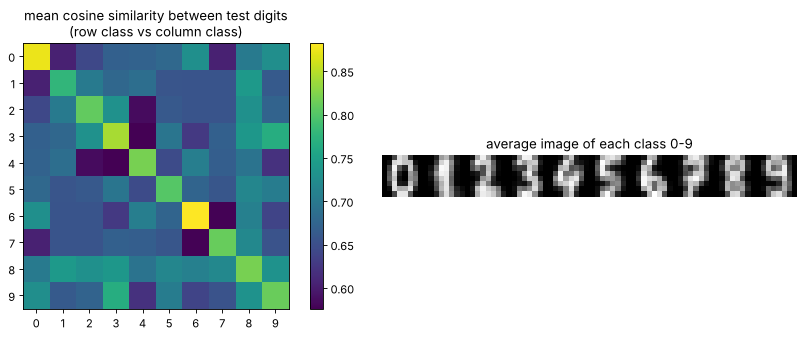

same-class similarity (diagonal) average: 0.825 | different-class average: 0.675
'nearest average image by dot product' classifier accuracy: 0.893


In [6]:
a = np.array([1, 2, 3]); b = np.array([2, 4, 6]); c = np.array([3, 0, -1])
print("a . b =", a @ b, "  (by hand: 1*2 + 2*4 + 3*6 = 28)")
cos = lambda u, v: float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))
print(f"cos(a, b) = {cos(a, b):.2f}  -> same direction (b is just 2a)")
print(f"cos(a, c) = {cos(a, c):.2f}  -> perpendicular, 'nothing in common'")

# Images as vectors: average cosine similarity between digit classes
means = np.array([X_train[y_train == d].mean(0) for d in range(10)])
S = np.array([[np.mean([cos(u, v) for u in X_test[y_test == i][:30] for v in X_test[y_test == j][:30]]) for j in range(10)] for i in range(10)])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
im = ax[0].imshow(S, cmap="viridis"); ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
ax[0].set_title("mean cosine similarity between test digits\n(row class vs column class)"); plt.colorbar(im, ax=ax[0])
ax[1].imshow(np.hstack([m.reshape(8, 8) for m in means]), cmap="gray"); ax[1].axis("off"); ax[1].set_title("average image of each class 0-9")
plt.tight_layout(); plt.show()
print("same-class similarity (diagonal) average:", S.diagonal().mean().round(3), "| different-class average:", S[~np.eye(10, dtype=bool)].mean().round(3))

# A one-line classifier: pick the class whose average image has the biggest cosine similarity
pred = np.argmax([[cos(x, m) for m in means] for x in X_test], axis=1)
print(f"'nearest average image by dot product' classifier accuracy: {(pred == y_test).mean():.3f}")

Digits of the same class have higher dot-product similarity than digits of different classes, and a classifier that just compares an image with each class's average image (10 dot products) already gets most digits right. **This is exactly what a neuron does: a dot product between its weights and its input.**

## 3 · Convolution = sliding dot product (by hand, then with OpenCV and PyTorch)

> **Analogy (Key Concepts):** a CNN is a detective with a **magnifying glass** (the kernel/filter) sliding over the image looking for clues (features).

At every position: put the 3×3 kernel on the image, multiply overlapping numbers, add them up (a dot product), write the result into the output, slide one step, repeat.

In [7]:
img6 = np.array([[10, 10, 10, 200, 200, 200]] * 6, dtype=np.float32)   # dark left half, bright right half
edge_kernel = np.array([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]], dtype=np.float32)                   # Sobel-x: responds to left-to-right brightness change
print("image:\n", img6.astype(int))

def conv2d_by_hand(image, kernel, verbose_at=None):
    kh, kw = kernel.shape
    out = np.zeros((image.shape[0] - kh + 1, image.shape[1] - kw + 1), np.float32)    # 'valid': no padding
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            window = image[i:i + kh, j:j + kw]
            out[i, j] = np.sum(window * kernel)          # the dot product of window and kernel
            if (i, j) == verbose_at:
                print(f"\nat output position {(i, j)}: window =\n{window.astype(int)}")
                print("window * kernel =\n", (window * kernel).astype(int), "\nsum =", out[i, j])
    return out

out = conv2d_by_hand(img6, edge_kernel, verbose_at=(0, 1))
print("\nfull output (4x4, because a 3x3 kernel fits 6-3+1 = 4 times per row):\n", out.astype(int))

image:
 [[ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]]

at output position (0, 1): window =
[[ 10  10 200]
 [ 10  10 200]
 [ 10  10 200]]
window * kernel =
 [[-10   0 200]
 [-20   0 400]
 [-10   0 200]] 
sum = 760.0

full output (4x4, because a 3x3 kernel fits 6-3+1 = 4 times per row):
 [[  0 760 760   0]
 [  0 760 760   0]
 [  0 760 760   0]
 [  0 760 760   0]]


Big numbers appear only where the window straddles the dark→bright edge; flat regions give 0. That is an **edge detector**.

Now the same thing on a real photo, and checks that **`cv2.filter2D`** and a PyTorch **`nn.Conv2d`** layer compute exactly the same numbers. (Strictly, all three compute *cross-correlation*: the kernel is not flipped. Deep learning calls this "convolution" anyway; for symmetric kernels there is no difference.)

output shapes: (510, 510) (510, 510) (510, 510)
by hand == cv2.filter2D : True
by hand == nn.Conv2d    : True
time: python loops 0.97s vs cv2.filter2D 0.8 ms


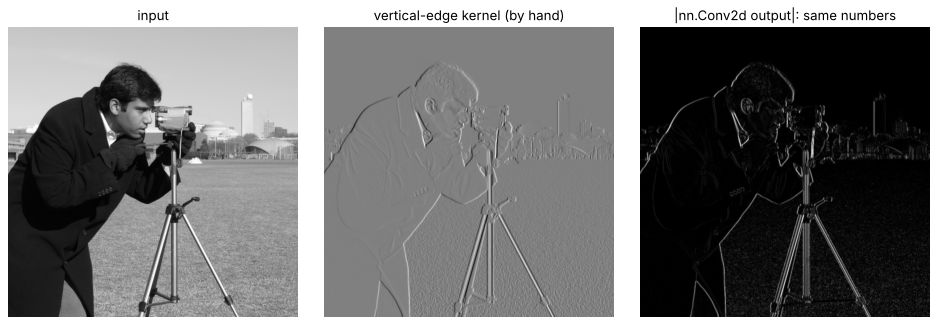

In [8]:
cam_f = cam.astype(np.float32)
t0 = time.perf_counter(); by_hand = conv2d_by_hand(cam_f, edge_kernel); t_hand = time.perf_counter() - t0

t0 = time.perf_counter()
cv_out = cv2.filter2D(cam_f, -1, edge_kernel)[1:-1, 1:-1]     # crop the border so the size matches 'valid'
t_cv = time.perf_counter() - t0

conv = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, bias=False)   # padding=0 -> 'valid', like ours
with torch.no_grad():
    conv.weight[:] = torch.from_numpy(edge_kernel)                            # paste the kernel in by hand
    torch_out = conv(torch.from_numpy(cam_f)[None, None])[0, 0].numpy()       # (H, W) -> (1, 1, H, W)

print("output shapes:", by_hand.shape, cv_out.shape, torch_out.shape)
print("by hand == cv2.filter2D :", np.allclose(by_hand, cv_out, atol=1e-2))
print("by hand == nn.Conv2d    :", np.allclose(by_hand, torch_out, atol=1e-2))
print(f"time: python loops {t_hand:.2f}s vs cv2.filter2D {t_cv * 1000:.1f} ms")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(cam, cmap="gray"); ax[0].set_title("input")
ax[1].imshow(by_hand, cmap="gray"); ax[1].set_title("vertical-edge kernel (by hand)")
ax[2].imshow(np.abs(torch_out), cmap="gray"); ax[2].set_title("|nn.Conv2d output|: same numbers")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**The bridge to CNNs in one sentence:** an `nn.Conv2d` layer is this sliding dot product, but instead of us typing the 9 kernel numbers, the network **learns** them (and learns dozens of kernels per layer) from labelled examples.

## 4 · Calculus: derivatives and gradients ("how steep the hill is")

- The **derivative** f′(x) is the **slope** of f at x: how fast f changes if x moves a tiny bit. We can estimate it numerically: f′(x) ≈ (f(x+h) − f(x−h)) / 2h.
- The **gradient** is the same idea in several dimensions: a vector of slopes, one per input, pointing in the **direction of steepest increase**.

> **Analogy (Key Concepts):** gradient = "how steep the hill is". If you are climbing, the gradient tells you how hard it gets, and which way is straight up.

x=-2: numerical slope -4.0000 | exact 2x = -4
x= 0: numerical slope  0.0000 | exact 2x = 0
x= 1: numerical slope  2.0000 | exact 2x = 2
x= 3: numerical slope  6.0000 | exact 2x = 6


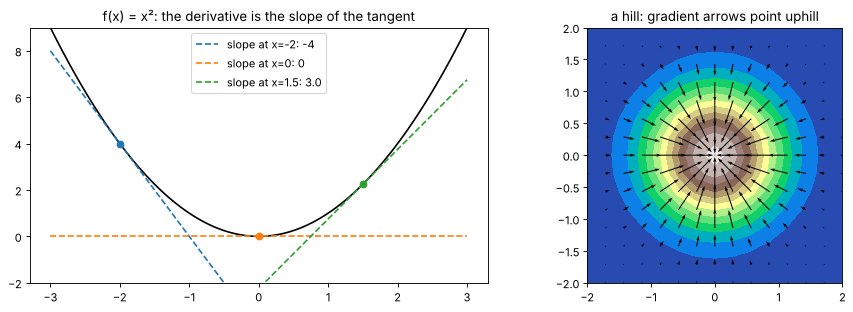

In [9]:
f = lambda x: x ** 2
df_exact = lambda x: 2 * x
num_deriv = lambda f, x, h=1e-4: (f(x + h) - f(x - h)) / (2 * h)
for x0 in [-2, 0, 1, 3]:
    print(f"x={x0:>2}: numerical slope {num_deriv(f, x0):7.4f} | exact 2x = {df_exact(x0)}")

xs = np.linspace(-3, 3, 100)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(xs, f(xs), "k")
for x0, col in [(-2, "C0"), (0, "C1"), (1.5, "C2")]:
    s = df_exact(x0); ax[0].plot(xs, f(x0) + s * (xs - x0), "--", color=col, label=f"slope at x={x0}: {s}")
    ax[0].plot(x0, f(x0), "o", color=col)
ax[0].set_ylim(-2, 9); ax[0].legend(); ax[0].set_title("f(x) = x²: the derivative is the slope of the tangent")

# 2-D: a hill z = exp(-(x²+y²)); arrows = gradient (points uphill, longer = steeper)
gx, gy = np.meshgrid(np.linspace(-2, 2, 15), np.linspace(-2, 2, 15))
z = np.exp(-(gx ** 2 + gy ** 2))
dzdx, dzdy = -2 * gx * z, -2 * gy * z
ax[1].contourf(gx, gy, z, 15, cmap="terrain"); ax[1].quiver(gx, gy, dzdx, dzdy, color="k")
ax[1].set_title("a hill: gradient arrows point uphill"); ax[1].set_aspect("equal")
plt.tight_layout(); plt.show()

**Image gradients are the same thing.** The Sobel kernel in section 3 *is* a derivative estimate of brightness in the x direction. Edges are where the brightness "hill" is steepest. (Day 13's HOG is built from these gradients.)

### A tiny gradient descent: how networks learn
To **minimise** a loss L(w), repeatedly step **downhill**: w ← w − learning_rate × L′(w). Below, L(w) = (w − 3)² + 1, whose minimum is at w = 3.

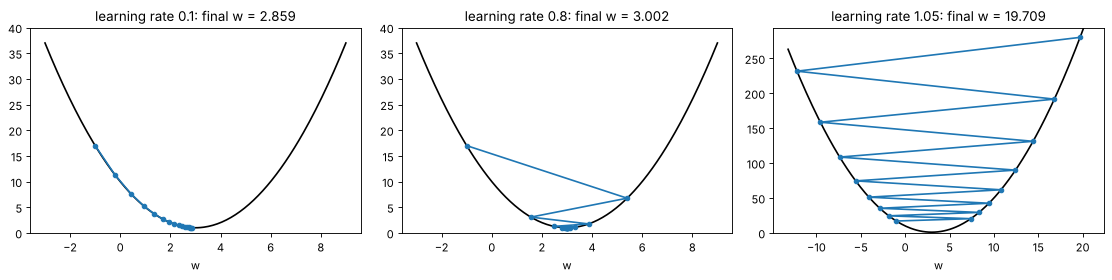

lr=0.1 : small steady steps, converges | lr=0.8 : overshoots, zig-zags in | lr=1.05 : every step overshoots more -> diverges


In [10]:
L = lambda w: (w - 3) ** 2 + 1
dL = lambda w: 2 * (w - 3)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ws = np.linspace(-2, 8, 100)
for a, lr in zip(ax, [0.1, 0.8, 1.05]):
    w, path = -1.0, [-1.0]
    for _ in range(15):
        w = w - lr * dL(w)          # the whole learning rule
        path.append(w)
    wsx = np.linspace(min(path + [-2]) - 1, max(path + [8]) + 1, 200)
    a.plot(wsx, L(wsx), "k"); a.plot(path, [L(p) for p in path], "o-", ms=4)
    a.set_title(f"learning rate {lr}: final w = {path[-1]:.3f}"); a.set_xlabel("w")
    a.set_ylim(0, max(40, 1.05 * max(L(p) for p in path)))
plt.tight_layout(); plt.show()
print("lr=0.1 : small steady steps, converges | lr=0.8 : overshoots, zig-zags in | lr=1.05 : every step overshoots more -> diverges")

learned m = 2.055, c = 0.998 (true values 2 and 1) | loss 52.24 -> 0.288


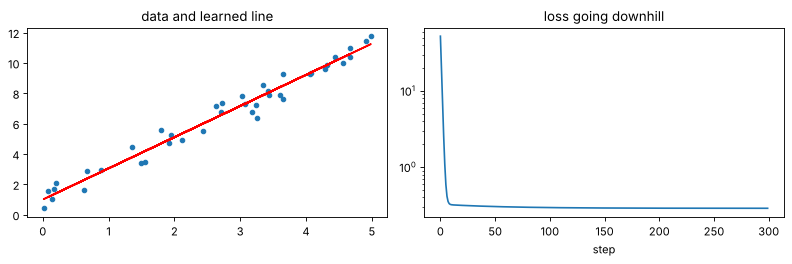

In [11]:
# Gradient descent fitting a line y = m*x + c to noisy points (two parameters -> a 2-D gradient)
rng = np.random.default_rng(0)
xd = rng.uniform(0, 5, 40); yd = 2.0 * xd + 1.0 + rng.normal(0, 0.5, 40)
m, c, lr, hist = 0.0, 0.0, 0.02, []
for step in range(300):
    err = (m * xd + c) - yd
    loss = np.mean(err ** 2)                         # mean squared error
    dm, dc = 2 * np.mean(err * xd), 2 * np.mean(err)  # the gradient (partial derivatives)
    m, c = m - lr * dm, c - lr * dc
    hist.append(loss)
print(f"learned m = {m:.3f}, c = {c:.3f} (true values 2 and 1) | loss {hist[0]:.2f} -> {hist[-1]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(xd, yd, "o", ms=4); ax[0].plot(xd, m * xd + c, "r"); ax[0].set_title("data and learned line")
ax[1].plot(hist); ax[1].set_yscale("log"); ax[1].set_xlabel("step"); ax[1].set_title("loss going downhill")
plt.tight_layout(); plt.show()

A neural network does exactly this, only with millions of parameters instead of two; `loss.backward()` in PyTorch computes all the partial derivatives (**backpropagation**) and `optimizer.step()` takes the downhill step.

## 5 · Probability and statistics: mean, variance, and why normalisation matters

- **Mean** μ = average value. **Variance** σ² = average squared distance from the mean; **standard deviation** σ = its square root (the typical spread).
- **Standardising** (z-score): x′ = (x − μ) / σ gives mean 0 and standard deviation 1. Day 15's `transforms.Normalize((0.1307,), (0.3081,))` is exactly this, using MNIST's mean and std.

digits pixels: mean 4.88, variance 36.20, std 6.02
after standardising: mean 0.00, std 1.00


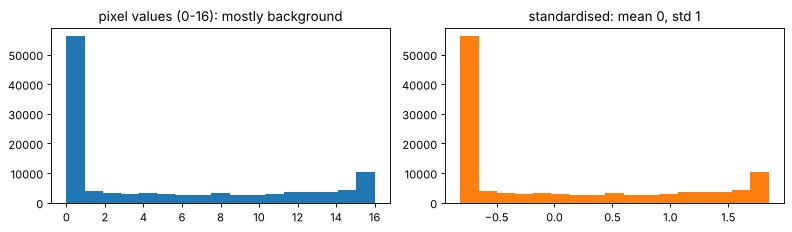

In [12]:
pix = digits.data.ravel()                 # every pixel value of every digit, 0-16
print(f"digits pixels: mean {pix.mean():.2f}, variance {pix.var():.2f}, std {pix.std():.2f}")
z = (pix - pix.mean()) / pix.std()
print(f"after standardising: mean {z.mean():.2f}, std {z.std():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(pix, bins=17); ax[0].set_title("pixel values (0-16): mostly background")
ax[1].hist(z, bins=17, color="C1"); ax[1].set_title("standardised: mean 0, std 1")
plt.tight_layout(); plt.show()

**Why does it matter?** Distance-based methods (kNN, k-means, RBF SVM) and gradient descent treat all features as comparable. If one feature is measured in much bigger units, it dominates everything. Experiment: add one useless feature to the digits, measured in "big units" (random numbers from 0 to 1000), and run kNN with and without standardisation.

In [13]:
from sklearn.preprocessing import StandardScaler

noise_tr = rng.uniform(0, 1000, (len(X_train), 1)); noise_te = rng.uniform(0, 1000, (len(X_test), 1))
Xtr_bad, Xte_bad = np.hstack([X_train, noise_tr]), np.hstack([X_test, noise_te])
print(f"kNN on the 64 pixels only            : {KNeighborsClassifier(3).fit(X_train, y_train).score(X_test, y_test):.3f}")
print(f"+ 1 useless feature in big units      : {KNeighborsClassifier(3).fit(Xtr_bad, y_train).score(Xte_bad, y_test):.3f}")
sc = StandardScaler().fit(Xtr_bad)          # learn mean/std on the TRAINING data only
print(f"same, after StandardScaler            : {KNeighborsClassifier(3).fit(sc.transform(Xtr_bad), y_train).score(sc.transform(Xte_bad), y_test):.3f}")

kNN on the 64 pixels only            : 0.989
+ 1 useless feature in big units      : 0.224
same, after StandardScaler            : 0.972


One badly scaled feature drowned out all 64 pixels; standardising put them back on an equal footing. For neural networks, normalised inputs also make gradient descent faster and more stable (the "hill" is round instead of a long narrow valley).

## 6 · Machine learning fundamentals: supervised vs unsupervised, side by side

| | Supervised (kNN) | Unsupervised (k-means) |
|---|---|---|
| Data given | images **and** labels | images **only** |
| Goal | predict the label of new images | discover groups by itself |
| Analogy (Key Concepts) | a teacher giving questions *with answers* | exploring a city *without a guide* |

Same 1,797 digits. kNN learns from labels; k-means (k = 10) is never told which digit is which.

SUPERVISED   kNN (with labels): test accuracy 0.989


UNSUPERVISED k-means (no labels): if each cluster is named after its majority digit, 0.792 of digits land in the 'right' cluster
   adjusted Rand index (0 = random grouping, 1 = perfect): 0.666
   cluster names: [0 1 7 1 3 6 4 5 9 2] -> digits never given their own cluster: [8]


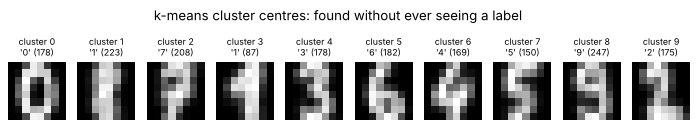

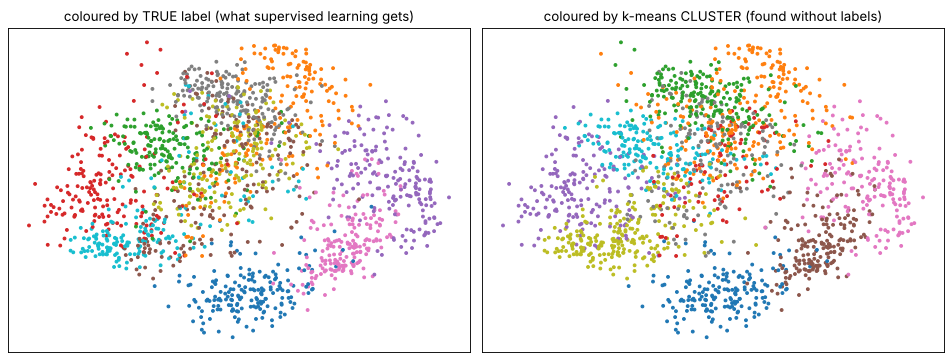

In [14]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Supervised
knn = KNeighborsClassifier(n_neighbors=3).fit(X_train, y_train)
print(f"SUPERVISED   kNN (with labels): test accuracy {knn.score(X_test, y_test):.3f}")

# Unsupervised: cluster ALL digits without labels
km = KMeans(n_clusters=10, random_state=0, n_init=10).fit(X)
clusters = km.labels_
# Only AFTER clustering do we peek at the labels to name each cluster by its most common digit
names = np.array([np.bincount(y[clusters == k], minlength=10).argmax() for k in range(10)])
acc = (names[clusters] == y).mean()
print(f"UNSUPERVISED k-means (no labels): if each cluster is named after its majority digit, {acc:.3f} of digits land in the 'right' cluster")
print(f"   adjusted Rand index (0 = random grouping, 1 = perfect): {adjusted_rand_score(y, clusters):.3f}")
print("   cluster names:", names, "-> digits never given their own cluster:", sorted(set(range(10)) - set(names)))

fig, ax = plt.subplots(1, 10, figsize=(11, 1.6))
for k in range(10):
    ax[k].imshow(km.cluster_centers_[k].reshape(8, 8), cmap="gray"); ax[k].axis("off")
    ax[k].set_title(f"cluster {k}\n'{names[k]}' ({(clusters == k).sum()})", fontsize=8)
plt.suptitle("k-means cluster centres: found without ever seeing a label", y=1.15); plt.show()

P = PCA(n_components=2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(P[:, 0], P[:, 1], c=y, cmap="tab10", s=6); ax[0].set_title("coloured by TRUE label (what supervised learning gets)")
ax[1].scatter(P[:, 0], P[:, 1], c=clusters, cmap="tab10", s=6); ax[1].set_title("coloured by k-means CLUSTER (found without labels)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

k-means discovers most digit groups on its own (the cluster centres look like digits!), but some digits get merged or split, and it can never *name* a group without labels. That is the difference: unsupervised learning finds structure; supervised learning learns the specific answer we want. (The 2-D plots use **PCA**, an unsupervised dimensionality-reduction method from the Key Concepts list, to squash 64 numbers into 2 for drawing.)

## 7 · The artificial neuron, by hand

**z = Σ wᵢxᵢ + b**, then **output = f(z)** where f is an activation function.

> **Analogy (Key Concepts):** inputs = evidence, weights = importance of each piece of evidence, bias = prior tendency, activation = the final decision.

Example: a neuron that should "fire" for a **vertical bar** in a 3×3 patch.

step 1  products w_i * x_i : [0 2 0 0 2 0 0 2 0]
step 2  sum = 6, plus bias -3.0 -> z = 3.0
step 3  sigmoid(z) = 0.953 | ReLU(z) = 3.0 | tanh(z) = 0.995

horizontal bar: z = -3.0 -> sigmoid 0.047, ReLU 0.0  (the neuron stays quiet)
PyTorch nn.Linear gives the same z: 3.0


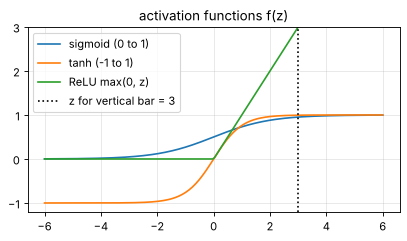

In [15]:
x = np.array([0, 1, 0,
              0, 1, 0,
              0, 1, 0], dtype=float)              # input: a vertical bar (9 pixel values)
wts = np.array([-1, 2, -1,
                -1, 2, -1,
                -1, 2, -1], dtype=float)          # weights: like the middle column, dislike the sides
b = -3.0                                          # bias: needs strong evidence before firing

z = np.sum(wts * x) + b
print("step 1  products w_i * x_i :", (wts * x).astype(int))
print(f"step 2  sum = {np.sum(wts * x):.0f}, plus bias {b} -> z = {z:.1f}")
sigmoid = lambda t: 1 / (1 + np.exp(-t)); relu = lambda t: np.maximum(0, t)
print(f"step 3  sigmoid(z) = {sigmoid(z):.3f} | ReLU(z) = {relu(z):.1f} | tanh(z) = {np.tanh(z):.3f}")

x_h = np.array([0, 0, 0, 1, 1, 1, 0, 0, 0], dtype=float)  # a HORIZONTAL bar
z_h = wts @ x_h + b
print(f"\nhorizontal bar: z = {z_h:.1f} -> sigmoid {sigmoid(z_h):.3f}, ReLU {relu(z_h):.1f}  (the neuron stays quiet)")

lin = nn.Linear(9, 1)                              # the same neuron in PyTorch
with torch.no_grad():
    lin.weight[:] = torch.tensor(wts, dtype=torch.float32); lin.bias[:] = b
print("PyTorch nn.Linear gives the same z:", lin(torch.tensor(x, dtype=torch.float32)).item())

t = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
for fn, name in [(sigmoid, "sigmoid (0 to 1)"), (np.tanh, "tanh (-1 to 1)"), (relu, "ReLU max(0, z)")]:
    plt.plot(t, fn(t), label=name)
plt.axvline(z, color="k", ls=":", label=f"z for vertical bar = {z:.0f}"); plt.legend(); plt.grid(alpha=.3); plt.ylim(-1.2, 3)
plt.title("activation functions f(z)"); plt.show()

Notice: this neuron's weights, laid out as 3×3, are an edge/line **kernel**. A convolution layer is just this neuron **re-used at every position** of the image.

**Why activations?** Without f, stacking layers is pointless: a linear function of a linear function is still linear. Non-linear activations let a network bend its decision boundaries.

## 8 · Neural network basics: a small feed-forward network (MLP) on digits

Layers: **input (64 pixels) → hidden (64 neurons, ReLU) → hidden (32, ReLU) → output (10 scores, one per digit)**.
- **Forward pass:** data flows forward and predictions are made.
- **Loss:** cross-entropy measures how wrong the predicted probabilities are.
- **Backpropagation:** `loss.backward()` sends the error backwards and computes every weight's gradient; `optimizer.step()` takes the downhill step (section 4).

> **Analogy (Key Concepts):** each neuron is a student giving a small opinion; the network combines them into a final decision.

Sequential(
  (0): Linear(in_features=64, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=10, bias=True)
)
trainable parameters: 6570 = (64*64+64) + (64*32+32) + (32*10+10)


trained 30 epochs in 15.4s
epoch  1: loss 2.232 | train acc 0.584 | test acc 0.565
epoch  2: loss 1.915 | train acc 0.698 | test acc 0.676
epoch  5: loss 0.527 | train acc 0.922 | test acc 0.889
epoch 10: loss 0.205 | train acc 0.963 | test acc 0.933
epoch 20: loss 0.099 | train acc 0.982 | test acc 0.956
epoch 30: loss 0.060 | train acc 0.987 | test acc 0.954


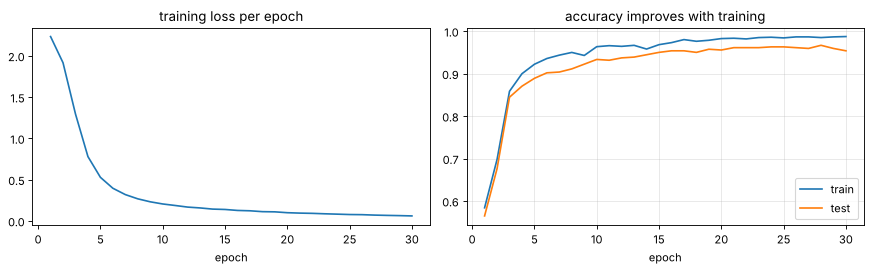

In [16]:
Xtr_t = torch.tensor(X_train, dtype=torch.float32); ytr_t = torch.tensor(y_train)
Xte_t = torch.tensor(X_test, dtype=torch.float32); yte_t = torch.tensor(y_test)

def make_mlp():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 10))

def train_mlp(model, Xtr, ytr, Xte, yte, epochs=30, lr=1e-3, batch=32):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = {"train": [], "test": [], "loss": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr)); tot = 0.0
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            out = model(Xtr[idx])                 # forward pass
            loss = loss_fn(out, ytr[idx])         # how wrong?
            opt.zero_grad(); loss.backward()      # backpropagation: gradients of every weight
            opt.step()                            # gradient-descent step
            tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            hist["train"].append((model(Xtr).argmax(1) == ytr).float().mean().item())
            hist["test"].append((model(Xte).argmax(1) == yte).float().mean().item())
        hist["loss"].append(tot / len(Xtr))
    return hist

mlp = make_mlp()
print(mlp)
print("trainable parameters:", sum(p.numel() for p in mlp.parameters()), "= (64*64+64) + (64*32+32) + (32*10+10)")
t0 = time.perf_counter()
hist = train_mlp(mlp, Xtr_t, ytr_t, Xte_t, yte_t)
print(f"trained 30 epochs in {time.perf_counter() - t0:.1f}s")
for ep in [0, 1, 4, 9, 19, 29]:
    print(f"epoch {ep + 1:>2}: loss {hist['loss'][ep]:.3f} | train acc {hist['train'][ep]:.3f} | test acc {hist['test'][ep]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(1, 31), hist["loss"]); ax[0].set_title("training loss per epoch"); ax[0].set_xlabel("epoch")
ax[1].plot(range(1, 31), hist["train"], label="train"); ax[1].plot(range(1, 31), hist["test"], label="test")
ax[1].set_title("accuracy improves with training"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

The Key Concepts activity, done: a small feed-forward network learns to classify digits and the accuracy climbs epoch by epoch (numbers printed above). The first-layer weights of each hidden neuron can even be viewed as 8×8 images:

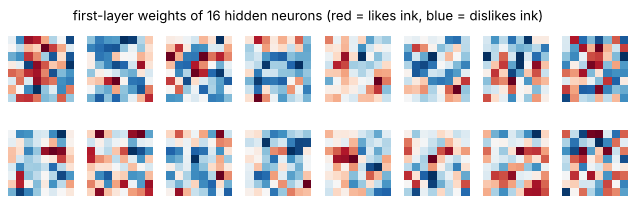

In [17]:
W = mlp[0].weight.detach().numpy()             # (64 neurons, 64 inputs)
fig, ax = plt.subplots(2, 8, figsize=(10, 2.8))
for a, wv in zip(ax.ravel(), W[:16]):
    a.imshow(wv.reshape(8, 8), cmap="RdBu"); a.axis("off")
plt.suptitle("first-layer weights of 16 hidden neurons (red = likes ink, blue = dislikes ink)"); plt.show()

## 9 · Bridge to CNNs

The Key Concepts list two problems with fully connected (dense) networks on images:

**Problem 1: too many parameters for large images.**

In [18]:
def n_params(layer):
    return sum(p.numel() for p in layer.parameters())

dense = nn.Linear(224 * 224 * 3, 1000)                    # every one of 1000 neurons sees all 150,528 input numbers
conv = nn.Conv2d(3, 64, kernel_size=3, padding=1)         # 64 filters, each 3x3x3, re-used at every position
print(f"input 224x224x3 = {224 * 224 * 3:,} numbers")
print(f"dense layer, 1000 neurons : {n_params(dense):>12,} parameters  (= 150,528 x 1000 weights + 1000 biases)")
print(f"conv layer, 64 3x3 filters: {n_params(conv):>12,} parameters  (= 64 x (3x3x3) weights + 64 biases)")
print(f"-> the dense layer has {n_params(dense) / n_params(conv):,.0f}x more parameters")
print(f"   memory for the dense layer's weights alone (float32): {n_params(dense) * 4 / 1e6:.0f} MB")

input 224x224x3 = 150,528 numbers
dense layer, 1000 neurons :  150,529,000 parameters  (= 150,528 x 1000 weights + 1000 biases)
conv layer, 64 3x3 filters:        1,792 parameters  (= 64 x (3x3x3) weights + 64 biases)
-> the dense layer has 84,001x more parameters
   memory for the dense layer's weights alone (float32): 602 MB


**Problem 2: dense layers ignore spatial structure.** A dense layer treats the image as a bag of independent numbers: it does not know which pixels are neighbours. Proof: **shuffle the pixel order** of every digit (the *same* random shuffle for all images) and retrain the MLP. To a human the images become noise; to the MLP nothing has changed.

MLP test accuracy, normal pixel order  : 0.954
MLP test accuracy, pixels SHUFFLED     : 0.965


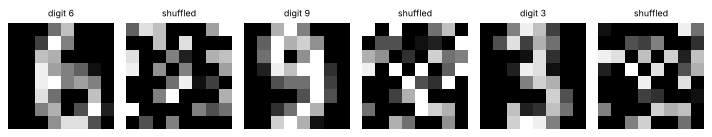

In [19]:
perm = np.random.default_rng(42).permutation(64)
Xtr_s, Xte_s = Xtr_t[:, perm], Xte_t[:, perm]
hist_s = train_mlp(make_mlp(), Xtr_s, ytr_t, Xte_s, yte_t)
print(f"MLP test accuracy, normal pixel order  : {hist['test'][-1]:.3f}")
print(f"MLP test accuracy, pixels SHUFFLED     : {hist_s['test'][-1]:.3f}")
fig, ax = plt.subplots(1, 6, figsize=(9, 1.8))
for i in range(3):
    ax[2 * i].imshow(X_test[i].reshape(8, 8), cmap="gray"); ax[2 * i].set_title(f"digit {y_test[i]}", fontsize=8)
    ax[2 * i + 1].imshow(X_test[i][perm].reshape(8, 8), cmap="gray"); ax[2 * i + 1].set_title("shuffled", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

The MLP does (about) equally well on scrambled images, so it was **never using the fact that neighbouring pixels belong together**. That is wasted knowledge: in real images, edges, corners and textures are *local* patterns. CNNs build this in:
- **Local connections:** each conv neuron looks at a small patch (3×3), like our edge kernel.
- **Weight sharing:** the same kernel slides over the whole image, so a pattern is recognised wherever it appears, with very few parameters.
- **Pooling:** summarises small regions, adding tolerance to small shifts (the 1-pixel shift that hurt kNN in section 1).

Section 3 applied an edge filter **manually**; on Day 15 a CNN **learns** its own filters from MNIST.

## 10 · Results, honestly

All numbers are from the run above.
- Transformations: kNN accuracy on digits fell from 98.9% (original) to 90.2% at 15°, 60.9% at 30°, 16.5% at 90°, 32.4% mirrored, and 61.7% with a mere 1-pixel shift: pixel-based recognition is fragile.
- Dot product as similarity: same-digit pairs averaged cosine 0.825 vs 0.675 for different digits; the "nearest average image" classifier reached 89.3% with just 10 dot products per image.
- Convolution by hand, `cv2.filter2D` and `nn.Conv2d` gave identical outputs; the Python loops took about a second, OpenCV well under a millisecond.
- Normalisation: one badly scaled useless feature dropped kNN from 98.9% to 22.4%; StandardScaler brought it back to 97.2%.
- Supervised kNN: 98.9% test accuracy. Unsupervised k-means: 79.2% of digits fall in a cluster whose majority label matches theirs (adjusted Rand index 0.666), without ever seeing a label; digit 8 never got a cluster of its own, while 1 was split into two clusters.
- MLP (6,570 parameters): test accuracy rose from 56.5% after epoch 1 to 95.4% after 30 epochs. That is *lower* than kNN's 98.9% on this tiny dataset (1,257 training images): neural networks need more data to shine. With shuffled pixels it scored 96.5%, the same within noise, which shows it ignores spatial layout.
- A dense layer on a 224×224×3 image with 1000 neurons has 150,529,000 parameters vs 1,792 for a 64-filter 3×3 conv layer.

## 11 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| Image arithmetic gives strange dark/bright spots | `uint8` wraps around (250 + 10 = 4) | Convert to a bigger type (`astype(np.int16)` or `float32`), then `np.clip(..., 0, 255).astype(np.uint8)` |
| `IndexError` / wrong crop | NumPy indexes `[row, column]` = `[y, x]`, OpenCV points are `(x, y)` | Remember: arrays are rows first |
| `RuntimeError: Expected 4D input` in `nn.Conv2d` | PyTorch wants `(batch, channels, H, W)` | Add axes: `t[None, None]` or `t.unsqueeze(0).unsqueeze(0)` |
| `RuntimeError: mat1 and mat2 shapes cannot be multiplied` | Input size does not match `nn.Linear(in_features, ...)` | Flatten correctly; check `x.shape` |
| Loss becomes `nan` or grows | Learning rate too large (like lr = 1.05 in section 4) | Lower the learning rate; normalise inputs |
| kNN / k-means results dominated by one feature | Features on different scales | `StandardScaler` fitted on the training data |
| `Can't call numpy() on Tensor that requires grad` | Tensor is part of the autograd graph | `.detach().numpy()` or compute inside `torch.no_grad()` |

## 12 · Try this yourself

1. Make your own 3×3 kernel that detects **horizontal** edges and run it with `conv2d_by_hand` on the camera image.
2. Change the bias of the "vertical bar" neuron to 0 and to −10. When does it fire for the horizontal bar? What is the bias doing?
3. In the gradient-descent cell, find the largest learning rate that still converges for L(w) = (w − 3)² + 1. (Hint: think about the slope 2(w − 3).)
4. Train the MLP with `nn.Sigmoid()` instead of `nn.ReLU()`. Is it slower to learn?
5. Run k-means with k = 20 instead of 10 and name clusters by majority label. Does the "accuracy" go up? Is that fair?
6. Augment the kNN training set with copies of each digit rotated by ±15° and re-test on the rotated test digits from section 1.

## 13 · Viva questions (with short model answers)

1. **How is an image stored in a computer?** As an array of numbers: H×W for grayscale (one channel), H×W×3 for colour (R, G, B channels), usually `uint8` values 0–255.
2. **Why does rotating or flipping an image hurt a pixel-based classifier?** The pixel values move to different positions, so the vector looks completely different, although the content is the same. Fixes: data augmentation, CNNs (convolution + pooling).
3. **What does the dot product measure?** How much two vectors point the same way (similarity); normalised, it is the cosine similarity.
4. **Why is convolution called a "sliding dot product"?** At each position the kernel is multiplied element-wise with the image patch under it and summed (a dot product), then it slides to the next position.
5. **What is the output size of a 3×3 convolution on a 6×6 image without padding?** 4×4 (6 − 3 + 1). In general (W − K + 2P)/S + 1.
6. **What is a derivative, and what is a gradient?** The derivative is the slope of a function at a point; the gradient is the vector of slopes for all inputs, pointing in the direction of steepest increase.
7. **What is gradient descent?** Repeatedly updating parameters by a small step against the gradient (downhill) to minimise the loss: w ← w − lr · ∂L/∂w.
8. **What happens if the learning rate is too large or too small?** Too large: overshoots and can diverge; too small: very slow convergence.
9. **What is normalisation (standardisation) and why does it matter?** Rescaling features to mean 0, std 1, so no feature dominates distances or gradients; it speeds up and stabilises training.
10. **Supervised vs unsupervised learning?** Supervised learns from labelled data to predict labels (kNN, SVM); unsupervised finds structure in unlabelled data (k-means, PCA).
11. **Write the equation of an artificial neuron.** z = Σ wᵢxᵢ + b, output = f(z) with an activation function such as ReLU or sigmoid.
12. **Why do we need activation functions?** Without them, any stack of layers collapses into one linear function and cannot learn non-linear patterns.
13. **What are forward pass and backpropagation?** Forward: compute outputs and the loss from inputs. Backpropagation: compute the gradient of the loss with respect to every weight by the chain rule, going backwards through the layers.
14. **Why are fully connected layers a poor fit for images?** Too many parameters (150 million for one 1000-neuron layer on a 224×224×3 image) and they ignore spatial structure (our shuffled-pixel MLP did just as well).
15. **What do CNNs add?** Local connections, weight sharing and pooling: far fewer parameters, spatial patterns detected anywhere in the image, tolerance to small shifts.